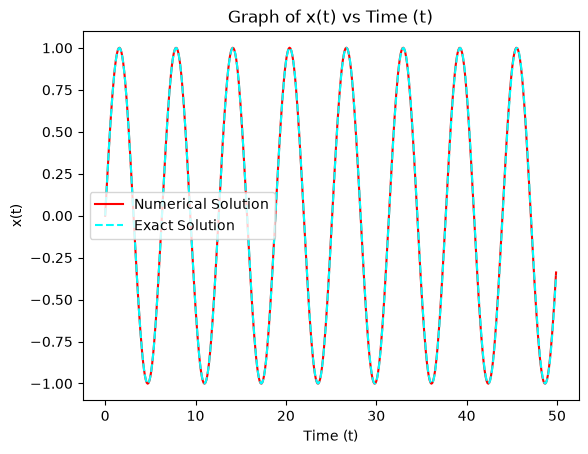

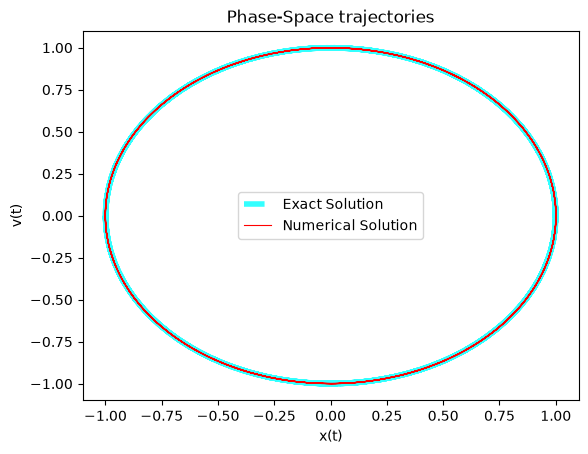

In [1]:
#PLANETARY MOTION QUESTION 1

#importing numpy for mathematical values and matplotlib to plot the graphs later on
import numpy as np
import matplotlib.pyplot as plt

# mx'' = =kx or x' = v , v' = -k/m * x
#writing out variables to be used later on
#setting arbitrary values for m,k,dt since they are not mentioned in the question
#m,k = 1 means that a = x which makes calculations easier
m = 1
k = 1
#small dt to minimise errors in the algorithm
dt = 0.1
#t = time steps x dt, setting maximum t equal to 50 to see multiple oscilations 
t_max = 50
#at time t=0 we want a base x and v, so making x=0 and v=1 as arbitrary values once again
x_0 = 0
v_0 = 1

#creating a function to figure out the acceleration, based on k,m,x
def acceleration (k, m, x):
    a = -(k/m)*x
    return a

#creating an array of times based on the max t and the dt set earlier
times = np.arange(0, t_max, dt)

#creating empty arrays for x and v to store our future values inside
x_values = np.zeros(len(times))
v_values = np.zeros(len(times))

#storing x_0 and v_0 inside these empty arrays
x_values[0] = x_0
v_values[0] = v_0

#(NUMERICAL SOLUTION)
#doing the velocity verlet algorithm using a for loop
#ignoring x_values[0],v_values[0] due to adding them to the arrays already, making the range 1 less than the length of the times
for i in range (len(times)-1):
    #getting values for a(x_k) to use in the velocity verlet algorithm
    a_k = acceleration(k, m, x_values[i])
    #finding x_k+1 (written as r_k+1 in the algorithm)
    x_values[i+1] = x_values[i] + (v_values[i]*dt) + ((1/2)*a_k*(dt**2))
    #using this to find a_k+1
    a_k_plus_1 = acceleration(k, m, x_values[i+1])
    #now finding v_k+1
    v_values[i+1] = v_values[i] + (1/2)*(a_k + a_k_plus_1) * dt

#(EXACT SOLUTION)
#starting with x(t) = A sin (sqrt(k/m)* t) + B cos (sqrt(k/m)*t)
# using my starting conditions of x_0 = 0 and v_0 = 1 , at t=0 , x(0) = 0, so 0 = A sin (0) + B cos (0), leading to B = 0
# therefore x(t) = A sin (sqrt(k/m)* t)
#now to find A, differentiate x(t)  : v(t) = A * sqrt(k/m) cos(sqrt(k/m)* t)
# v(0) = 1, so 1 = A * sqrt (k/m), means A = sqrt (m/k)
# so :
# x(t) = sqrt(m/k) * sin (sqrt(k/m) * t)
# v(t) = sqrt(m/k) * sqrt (k/m) * cos(sqrt(k/m) * t)  =  cos(sqrt(k/m) * t)

# using this, code the values for the exact x(t) and v(t)
x_exact = np.sqrt(m/k) * np.sin(np.sqrt(k/m) * times)
v_exact = np.cos(np.sqrt(k/m) * times)

#plotting the x(t) and the phase-space trajectories (x(t) , v(t)) for both
#first plot of x(t) for both the numerical solution and exact solution
plt.plot(times, x_values , label = 'Numerical Solution', color = 'red')
#making the exact solution a dashed line so it can be seen against the numerical solution
plt.plot(times, x_exact, linestyle = '--', label = 'Exact Solution', color = 'aqua')
#adding a title
plt.title('Graph of x(t) vs Time (t)')
#labelling the axes
plt.xlabel('Time (t)')
plt.ylabel('x(t)')
#adding a legend
plt.legend()
plt.show()

#plotting (x(t), v(t))
#plotting exact solution first because i need to make it more transparent and larger, as when i put it second it was covering the numerical solution
plt.plot(x_exact, v_exact, linestyle = '--', label = 'Exact Solution', color = 'aqua', alpha = 0.8, linewidth = 4)
#the numerical solution, editing this width a bit too to make it more visible
plt.plot(x_values, v_values , label = 'Numerical Solution', color = 'red', linewidth = 0.8)

#adding a title
plt.title('Phase-Space trajectories')
#adding labels
plt.xlabel('x(t)')
plt.ylabel('v(t)')
#legend
plt.legend()
plt.show()